In [1]:

import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

# Sample sales dataset
data = {
    "order_id": [1001, 1002, 1003, 1004, 1005, 1006,
                 1007, 1008, 1009, 1010, 1011, 1012],
    "order_date": [
        "2026-01-05", "2026-01-08", "2026-01-12",
        "2026-02-03", "2026-02-10", "2026-02-15",
        "2026-03-02", "2026-03-08", "2026-03-12",
        "2026-03-20", "2026-04-05", "2026-04-18"
    ],
    "region": [
        "North", "South", "East", "North", "West", "South",
        "East", "North", "West", "South", "East", "North"
    ],
    "product": [
        "Laptop", "Mouse", "Keyboard", "Monitor", "Laptop",
        "Mouse", "Laptop", "Keyboard", "Monitor", "Keyboard",
        "Mouse", "Laptop"
    ],
    "category": [
        "Electronics", "Accessories", "Accessories", "Electronics",
        "Electronics", "Accessories", "Electronics", "Accessories",
        "Electronics", "Accessories", "Accessories", "Electronics"
    ],
    "quantity": [2, 5, 3, 2, 1, 10, 1, 4, 3, 2, 8, 1],
    "unit_price": [800, 20, 45, 200, 800, 20, 800, 45, 200, 45, 20, 800]
}

df = pd.DataFrame(data)
df["order_date"] = pd.to_datetime(df["order_date"])
df["revenue"] = df["quantity"] * df["unit_price"]

print("Dataset created successfully!")
print("Rows and columns:", df.shape)
display(df.head())


Dataset created successfully!
Rows and columns: (12, 8)


,order_id,order_date,region,product,category,quantity,unit_price,revenue
0,1001,2026-01-05,North,Laptop,Electronics,2,800,1600
1,1002,2026-01-08,South,Mouse,Accessories,5,20,100
2,1003,2026-01-12,East,Keyboard,Accessories,3,45,135
3,1004,2026-02-03,North,Monitor,Electronics,2,200,400
4,1005,2026-02-10,West,Laptop,Electronics,1,800,800


In [2]:

print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate order IDs:")
print(df["order_id"].duplicated().sum())

print("\nTotal revenue: ₹", df["revenue"].sum())
print("Total units sold:", df["quantity"].sum())
print("Number of orders:", df["order_id"].nunique())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   order_id    12 non-null     int64         
 1   order_date  12 non-null     datetime64[ns]
 2   region      12 non-null     object        
 3   product     12 non-null     object        
 4   category    12 non-null     object        
 5   quantity    12 non-null     int64         
 6   unit_price  12 non-null     int64         
 7   revenue     12 non-null     int64         
dtypes: datetime64[ns](1), int64(4), object(3)
memory usage: 900.0+ bytes

Missing values:
order_id      0
order_date    0
region        0
product       0
category      0
quantity      0
unit_price    0
revenue       0
dtype: int64

Duplicate order IDs:
0

Total revenue: ₹ 5865
Total units sold: 42
Number of orders: 12


In [3]:

# Create an in-memory SQL database
conn = sqlite3.connect(":memory:")

# Load our pandas DataFrame into a SQL table
df.to_sql("sales", conn, index=False, if_exists="replace")

# Test that SQL can read the data
query = """
SELECT COUNT(*) AS total_orders,
       SUM(quantity * unit_price) AS total_revenue
FROM sales;
"""

display(pd.read_sql_query(query, conn))


,total_orders,total_revenue
0,12,5865


In [4]:

query = """
SELECT product,
       SUM(quantity * unit_price) AS revenue
FROM sales
GROUP BY product
ORDER BY revenue DESC;
"""

display(pd.read_sql_query(query, conn))


,product,revenue
0,Laptop,4000
1,Monitor,1000
2,Mouse,460
3,Keyboard,405


In [5]:

query = """
SELECT strftime('%Y-%m', order_date) AS month,
       SUM(quantity * unit_price) AS revenue
FROM sales
GROUP BY month
ORDER BY month;
"""

monthly_sales = pd.read_sql_query(query, conn)
display(monthly_sales)


,month,revenue
0,2026-01,1835
1,2026-02,1400
2,2026-03,1670
3,2026-04,960


In [6]:

query = """
SELECT region,
       SUM(quantity * unit_price) AS revenue
FROM sales
GROUP BY region
ORDER BY revenue DESC;
"""

display(pd.read_sql_query(query, conn))


,region,revenue
0,North,2980
1,West,1400
2,East,1095
3,South,390


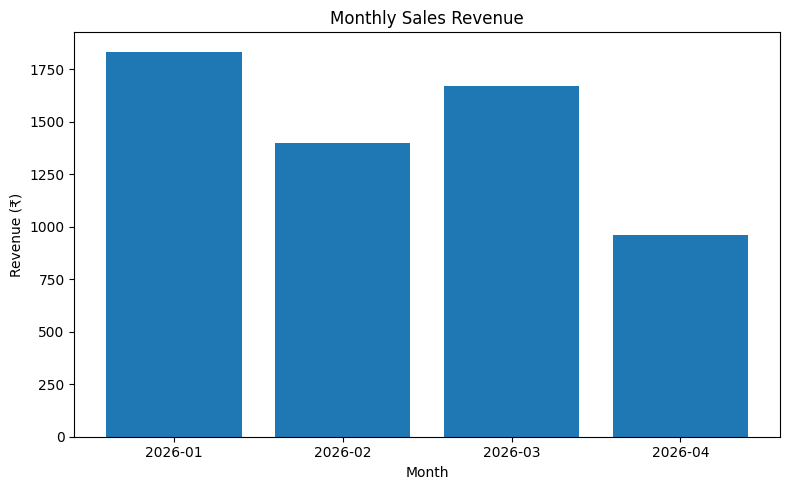

In [7]:

plt.figure(figsize=(8, 5))
plt.bar(monthly_sales["month"], monthly_sales["revenue"])
plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.tight_layout()
plt.show()


In [8]:

df.to_csv("sales_data.csv", index=False)
monthly_sales.to_csv("monthly_sales_analysis.csv", index=False)

print("Files saved successfully:")
print("1. sales_data.csv")
print("2. monthly_sales_analysis.csv")


Files saved successfully:
1. sales_data.csv
2. monthly_sales_analysis.csv
